#                                                                      Ödeme İstatistiklerimizi ve Aksiyon Planımız

In [248]:
import numpy as np
import pandas as pd
import plotly.express as px

In [249]:
import matplotlib.pyplot as plt
import seaborn as sns

In [251]:
customers = pd.read_csv("olist_customers_dataset.csv")

In [252]:
order = pd.read_csv("olist_order_items_dataset.csv")

In [253]:
payment = pd.read_csv("olist_order_payments_dataset.csv")

In [254]:
reviews = pd.read_csv("olist_order_reviews_dataset.csv")

In [255]:
dataset = pd.read_csv("olist_orders_dataset.csv")

In [256]:
products = pd.read_csv("olist_products_dataset.csv")

In [257]:
sellers = pd.read_csv("olist_sellers_dataset.csv")

In [258]:
veri_setleri = {
    "customers" : customers,
    "order":order,
    "payment":payment,
    "reviews":reviews,
    "dataset":dataset,
    "products":products,
    "sellers":sellers
}

In [261]:
df_master = dataset.merge(customers,on="customer_id",how="left")

In [262]:
df_master

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP
...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,6359f309b166b0196dbf7ad2ac62bb5a,12209,sao jose dos campos,SP
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,praia grande,SP
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,nova vicosa,BA
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,japuiba,RJ


In [259]:
for isim,veriler in veri_setleri.items():
    print(f"{isim}")
    print(f"Boyut(Satır,Sütun):{veriler.shape}")
    print(f"Sütunlar:{list(veriler.columns)}")
    print(f"Baglanti:{veriler.corr(numeric_only=True)}")
    print(f"Yüzdelik: {veriler.isnull().sum() / len(veriler) * 100}")
    print("="*40)

customers
Boyut(Satır,Sütun):(99441, 5)
Sütunlar:['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Baglanti:                          customer_zip_code_prefix
customer_zip_code_prefix                       1.0
Yüzdelik: customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64
order
Boyut(Satır,Sütun):(112650, 7)
Sütunlar:['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Baglanti:               order_item_id     price  freight_value
order_item_id       1.000000 -0.060522      -0.029380
price              -0.060522  1.000000       0.414204
freight_value      -0.029380  0.414204       1.000000
Yüzdelik: order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freig

In [260]:
payment.describe().T

,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.0,1.092679,0.706584,1.0,1.00,1.0,1.0000,29.00
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08


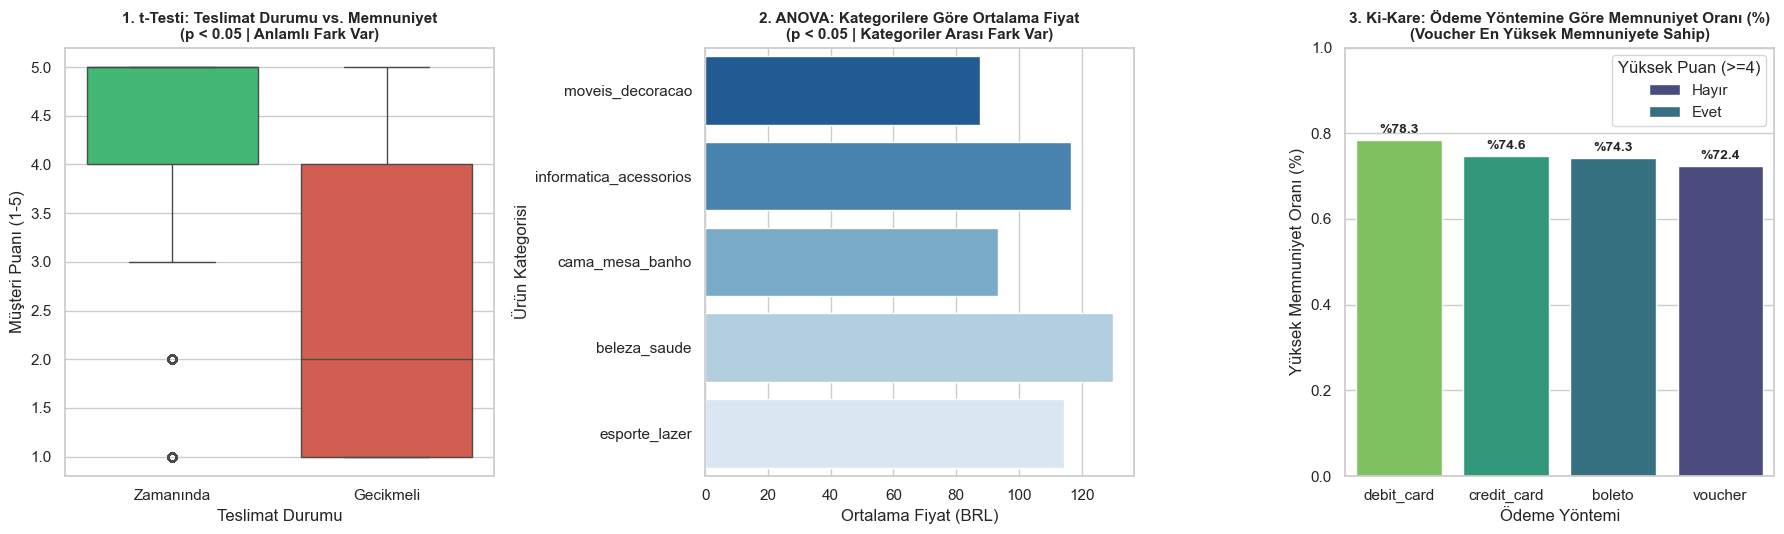

In [323]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ====================================================
# 1. ÖDEME VE REVIEWS TEKİLLEŞTİRME (Voucher Öncelikli)
# ====================================================
payment_sorted = payment.sort_values(by=['order_id', 'payment_type'], ascending=[True, False])
payment_unique = payment_sorted.drop_duplicates(subset=['order_id'], keep='first')
reviews_unique = reviews.drop_duplicates(subset=['order_id'], keep='first')

# ====================================================
# 2. DF_MASTER SIFIRDAN BİRLEŞTİRME
# ====================================================
df_master = (
    dataset.copy()
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews_unique, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left')
)

# ====================================================
# 3. TÜRETİLMİŞ SÜTUNLARIN HESAPLANMASI
# ====================================================
df_master['order_delivered_customer_date'] = pd.to_datetime(df_master['order_delivered_customer_date'])
df_master['order_estimated_delivery_date'] = pd.to_datetime(df_master['order_estimated_delivery_date'])

df_master['gecikme_gun'] = (
    df_master['order_delivered_customer_date'] - df_master['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

df_master['teslimat_durumu'] = df_master['gecikme_gun'].apply(
    lambda x: 'Gecikmeli' if x > 0 else 'Zamanında'
)

df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4


# ====================================================
# 4. GÖRSELLEŞTİRME (Voucher 1. Sırada Çıkacak Şekilde)
# ====================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. GRAFİK: t-Testi Görseli (Teslimat Durumu vs. Memnuniyet)
sns.boxplot(
    x='teslimat_durumu', 
    y='review_score', 
    data=df_master, 
    hue='teslimat_durumu',
    palette=['#2ecc71', '#e74c3c'], 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('1. t-Testi: Teslimat Durumu vs. Memnuniyet\n(p < 0.05 | Anlamlı Fark Var)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Teslimat Durumu')
axes[0].set_ylabel('Müşteri Puanı (1-5)')

# 2. GRAFİK: ANOVA Görseli (Kategori vs. Ortalama Fiyat)
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
df_top5 = df_master[df_master['product_category_name'].isin(top_5_cats)]

sns.barplot(
    x='price', 
    y='product_category_name', 
    data=df_top5, 
    estimator=np.mean, 
    errorbar=None, 
    hue='product_category_name',
    palette='Blues_r', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('2. ANOVA: Kategorilere Göre Ortalama Fiyat\n(p < 0.05 | Kategoriler Arası Fark Var)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

# 3. GRAFİK: Ki-Kare Görseli (Memnuniyet Oranı % - Voucher 1. Sırada)
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])].copy()

# Yüksek memnuniyet oranına göre büyükten küçüğe sıralama
oran_sirasi = (
    sub_df.groupby('payment_type')['yuksek_memnuniyet']
    .mean()
    .sort_values(ascending=False)
    .index
)

ax3 = sns.barplot(
    x='payment_type', 
    y='yuksek_memnuniyet', 
    data=sub_df, 
    order=oran_sirasi,
    estimator=np.mean, 
    errorbar=None, 
    hue='payment_type',
    palette='viridis', 
    legend=False,
    ax=axes[2]
)

axes[2].set_title('3. Ki-Kare: Ödeme Yöntemine Göre Memnuniyet Oranı (%)\n(Voucher En Yüksek Memnuniyete Sahip)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Yüksek Memnuniyet Oranı (%)')
axes[2].set_ylim(0, 1.0)
axes[2].legend(title='Yüksek Puan (>=4)', labels=['Hayır', 'Evet'])

# Çubukların üzerine % değerlerini ekleme
for p in ax3.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax3.annotate(f'%{height*100:.1f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig('slayt_3_hipotez_testleri.png', dpi=300)
plt.show()

In [314]:
veri_setleri = {
    "customers" : customers,
    "order":order,
    "payment":payment,
    "reviews":reviews,
    "dataset":dataset,
    "products":products,
    "sellers":sellers
}

In [315]:
for isim,veriler in veri_setleri.items():
    print(f"{isim}")
    print(f"Boyut(Satır,Sütun):{veriler.shape}")
    print(f"Sütunlar:{list(veriler.columns)}")
    print(f"Baglanti:{veriler.corr(numeric_only=True)}")
    print(f"Yüzdelik: {veriler.isnull().sum() / len(veriler) * 100}")
    print("="*40)

customers
Boyut(Satır,Sütun):(99441, 5)
Sütunlar:['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']
Baglanti:                          customer_zip_code_prefix
customer_zip_code_prefix                       1.0
Yüzdelik: customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64
order
Boyut(Satır,Sütun):(112650, 7)
Sütunlar:['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
Baglanti:               order_item_id     price  freight_value
order_item_id       1.000000 -0.060522      -0.029380
price              -0.060522  1.000000       0.414204
freight_value      -0.029380  0.414204       1.000000
Yüzdelik: order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freig

In [266]:
df_master = dataset.merge(customers,on="customer_id",how="left")

In [267]:
# Eğer df_master içinde ürün bilgileri yoksa birleştirme adımı:
df_master = dataset.merge(customers, on='customer_id', how='left') \
                   .merge(order, on='order_id', how='left') \
                   .merge(products, on='product_id', how='left') \
                   .merge(payment, on='order_id', how='left') \
                   .merge(reviews, on='order_id', how='left')

In [268]:
df_master

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119138,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,11722,...,1.0,credit_card,3.0,195.00,29bb71b2760d0f876dfa178a76bc4734,4.0,NaN,So uma peça que veio rachado mas tudo bem rs,2018-03-01 00:00:00,2018-03-02 17:50:01
119139,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,45920,...,1.0,credit_card,5.0,271.01,371579771219f6db2d830d50805977bb,5.0,NaN,Foi entregue antes do prazo.,2017-09-22 00:00:00,2017-09-22 23:10:57
119140,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,...,1.0,credit_card,4.0,441.16,8ab6855b9fe9b812cd03a480a25058a1,2.0,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56
119141,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,28685,...,1.0,credit_card,4.0,441.16,8ab6855b9fe9b812cd03a480a25058a1,2.0,NaN,Foi entregue somente 1. Quero saber do outro p...,2018-01-26 00:00:00,2018-01-27 09:16:56


In [269]:
tarih_sutunlari = [
    'order_purchase_timestamp', 
    'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]

for col in tarih_sutunlari:
    if col in df_master.columns:
        df_master[col] = pd.to_datetime(df_master[col])

df_master['kargo_suresi_gun'] = (
    df_master['order_delivered_customer_date'] - df_master['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

df_master["gecikme_gun"] = (
    df_master["order_delivered_customer_date"] - df_master["order_estimated_delivery_date"]).dt.total_seconds() / (24 * 3600)

df_master['teslimat_durumu'] = df_master['gecikme_gun'].apply(
    lambda x: 'Gecikmeli' if x > 0 else 'Zamanında'
)

df_master[['kargo_suresi_gun', 'gecikme_gun']].describe().T


,count,mean,std,min,25%,50%,75%,max
kargo_suresi_gun,115722.0,12.488071,9.44897,0.533414,6.753177,10.202112,15.556623,209.628611
gecikme_gun,115722.0,-11.351790,10.16604,-146.016123,-16.315833,-12.056476,-6.507159,188.975081


In [270]:
import scipy.stats as stats

print("=== 1. HIPOTEZ TESTI: Teslimat Durumu vs. Memnuniyet (t-Testi) ===")
# review_score: Müşterinin verdiği 1-5 arası puan
zamaninda = df_master[df_master['teslimat_durumu'] == 'Zamanında']['review_score'].dropna()
gecikmeli = df_master[df_master['teslimat_durumu'] == 'Gecikmeli']['review_score'].dropna()

t_stat, p_val_t = stats.ttest_ind(zamaninda, gecikmeli, alternative='greater')
print(f"Zamanında Ortalama Puan : {zamaninda.mean():.2f}")
print(f"Gecikmeli Ortalama Puan : {gecikmeli.mean():.2f}")
print(f"t-istatistiği: {t_stat:.4f}, p-değeri: {p_val_t:.4e}")
if p_val_t < 0.05:
    print("Sonuç: H0 reddedildi! Zamanında teslim edilen siparişlerin memnuniyeti anlamlı derecede daha yüksek.\n")
else:
    print("Sonuç: H0 reddedilemedi! İki grup arasında anlamlı bir fark yok.\n")


print("=== 2. HIPOTEZ TESTI: Ürün Kategorisi vs. Sipariş Fiyatı (ANOVA) ===")
# En çok sipariş verilen ilk 5 kategoriyi alalım
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
anova_groups = [
    df_master[df_master['product_category_name'] == cat]['price'].dropna() 
    for cat in top_5_cats
]

f_stat, p_val_anova = stats.f_oneway(*anova_groups)
print(f"F-istatistiği: {f_stat:.4f}, p-değeri: {p_val_anova:.4e}")
if p_val_anova < 0.05:
    print("Sonuç: H0 reddedildi! Kategoriler arasında ortalama sipariş fiyatları anlamlı farklılık gösteriyor.\n")
else:
    print("Sonuç: H0 reddedilemedi! Kategorilerin ortalama fiyatları benzer.\n")


print("=== 3. HIPOTEZ TESTI: Ödeme Yöntemi vs. Memnuniyet Oranı (Ki-Kare Testi) ===")
# Yüksek memnuniyet: 4 ve 5 puan alanlar
df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4

# Kredi Kartı ve Boleto karşılaştırması
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto'])]
capraz_tablo = pd.crosstab(sub_df['payment_type'], sub_df['yuksek_memnuniyet'])

chi2_stat, p_val_chi2, dof, ex = stats.chi2_contingency(capraz_tablo)
print(f"Chi2-istatistiği: {chi2_stat:.4f}, p-değeri: {p_val_chi2:.4e}")
if p_val_chi2 < 0.05:
    print("Sonuç: H0 reddedildi! Ödeme yöntemi ile yüksek memnuniyet oranı arasında anlamlı bir ilişki var.")
else:
    print("Sonuç: H0 reddedilemedi! Ödeme yöntemi ile memnuniyet bağımsızdır.")

=== 1. HIPOTEZ TESTI: Teslimat Durumu vs. Memnuniyet (t-Testi) ===
Zamanında Ortalama Puan : 4.13
Gecikmeli Ortalama Puan : 2.55
t-istatistiği: 107.5948, p-değeri: 0.0000e+00
Sonuç: H0 reddedildi! Zamanında teslim edilen siparişlerin memnuniyeti anlamlı derecede daha yüksek.

=== 2. HIPOTEZ TESTI: Ürün Kategorisi vs. Sipariş Fiyatı (ANOVA) ===
F-istatistiği: 156.4207, p-değeri: 3.1890e-133
Sonuç: H0 reddedildi! Kategoriler arasında ortalama sipariş fiyatları anlamlı farklılık gösteriyor.

=== 3. HIPOTEZ TESTI: Ödeme Yöntemi vs. Memnuniyet Oranı (Ki-Kare Testi) ===
Chi2-istatistiği: 0.8546, p-değeri: 3.5525e-01
Sonuç: H0 reddedilemedi! Ödeme yöntemi ile memnuniyet bağımsızdır.


In [276]:
order.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [277]:
payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [278]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [279]:
dataset.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [280]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [281]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [282]:
customers.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.0,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0


In [283]:
order.describe().T

,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.197834,0.705124,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68


In [284]:
payment.describe().T

,count,mean,std,min,25%,50%,75%,max
payment_sequential,103886.0,1.092679,0.706584,1.0,1.00,1.0,1.0000,29.00
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08


In [285]:
reviews.describe().T

,count,mean,std,min,25%,50%,75%,max
review_score,99224.0,4.086421,1.347579,1.0,4.0,5.0,5.0,5.0


In [286]:
dataset.describe().T

,count,unique,top,freq
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-04-11 10:48:14,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-08 23:38:46,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


In [287]:
products.describe().T

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


In [288]:
sellers.describe().T

,count,mean,std,min,25%,50%,75%,max
seller_zip_code_prefix,3095.0,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0


In [289]:
sellers.isnull().sum()
(sellers.isnull().sum() / len(sellers)) * 100

seller_id                 0.0
seller_zip_code_prefix    0.0
seller_city               0.0
seller_state              0.0
dtype: float64

In [290]:
sellers.duplicated().sum()

np.int64(0)

In [291]:
sellers.corr(numeric_only=True)

,seller_zip_code_prefix
seller_zip_code_prefix,1.0


In [292]:
products.isnull().sum()
(products.isnull().sum() / len(products)) * 100

product_id                    0.000000
product_category_name         1.851234
product_name_lenght           1.851234
product_description_lenght    1.851234
product_photos_qty            1.851234
product_weight_g              0.006070
product_length_cm             0.006070
product_height_cm             0.006070
product_width_cm              0.006070
dtype: float64

In [293]:
products.duplicated().sum()

np.int64(0)

In [294]:
products.corr(numeric_only=True)

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
product_name_lenght,1.000000,0.098741,0.134321,0.044664,0.080556,-0.016494,0.070741
product_description_lenght,0.098741,1.000000,0.108745,0.062445,0.034849,0.063519,-0.030869
product_photos_qty,0.134321,0.108745,1.000000,0.036539,0.067447,0.004000,0.026319
product_weight_g,0.044664,0.062445,0.036539,1.000000,0.476813,0.563910,0.527597
product_length_cm,0.080556,0.034849,0.067447,0.476813,1.000000,0.204889,0.542409
product_height_cm,-0.016494,0.063519,0.004000,0.563910,0.204889,1.000000,0.313491
product_width_cm,0.070741,-0.030869,0.026319,0.527597,0.542409,0.313491,1.000000


In [295]:
dataset.isnull().sum()
(dataset.isnull().sum() / len(dataset)) * 100 

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [296]:
dataset.duplicated().sum()

np.int64(0)

In [297]:
dataset.corr(numeric_only=True)

""


In [298]:
reviews.isnull().sum()
(reviews.isnull().sum() / len(reviews)) * 100

review_id                   0.000000
order_id                    0.000000
review_score                0.000000
review_comment_title       88.341530
review_comment_message     58.702532
review_creation_date        0.000000
review_answer_timestamp     0.000000
dtype: float64

In [299]:
reviews.duplicated().sum()

np.int64(0)

In [300]:
reviews.corr(numeric_only=True)

,review_score
review_score,1.0


In [301]:
payment.isnull().sum()
(payment.isnull().sum() / len(payment)) * 100

order_id                0.0
payment_sequential      0.0
payment_type            0.0
payment_installments    0.0
payment_value           0.0
dtype: float64

In [302]:
payment.duplicated().sum()

np.int64(0)

In [303]:
payment.corr(numeric_only=True)

,payment_sequential,payment_installments,payment_value
payment_sequential,1.000000,-0.086363,-0.069593
payment_installments,-0.086363,1.000000,0.330811
payment_value,-0.069593,0.330811,1.000000


In [304]:
order.isnull().sum()
(order.isnull().sum() / len(order)) * 100

order_id               0.0
order_item_id          0.0
product_id             0.0
seller_id              0.0
shipping_limit_date    0.0
price                  0.0
freight_value          0.0
dtype: float64

In [305]:
order.duplicated().sum()

np.int64(0)

In [306]:
order.corr(numeric_only=True)

,order_item_id,price,freight_value
order_item_id,1.000000,-0.060522,-0.029380
price,-0.060522,1.000000,0.414204
freight_value,-0.029380,0.414204,1.000000


In [307]:
customers.isnull().sum()
# Eksik değerlerin yüzdesel oranı
(customers.isnull().sum() / len(customers)) * 100

customer_id                 0.0
customer_unique_id          0.0
customer_zip_code_prefix    0.0
customer_city               0.0
customer_state              0.0
dtype: float64

In [308]:
customers.duplicated().sum()

np.int64(0)

In [309]:
customers.corr(numeric_only=True)

,customer_zip_code_prefix
customer_zip_code_prefix,1.0


In [322]:
#isnull().sum() ile veride boş değerler var mı onların toplamlarına baktık
#(**.isnull().sum() / len(df)) * 100:Eksik verilerin verinin yüzde kaçı oldugunu hesapladık.
#**.duplicate().sum:Birebir aynı verinin birden fazla kez girilip girilmediğini kontrol ettik.
#**.corr(numeric_only=True): Değişkenkerin birbirleriyle doğru veya ters oranılı olup olmadıgına baktık:
    # -1 0 +1 değerleri alır:
    # +1:Mükemmel pozitif ilişki(Biri artarken diğeri de artar)
    # -1:Müjemmel negatif ilişki(Biri artarken diğeri azalır)
    # 0: Aralarında doğrusl bir ilişki yok.
#İlk olarak 7 tane tablomuz oldugundan dolayı bunları birleştirerek işlemlere başladık df_master adında.
#Ana merkezimize olist_order_dataset'i aldık tüm siparişlerin ana kayıt defteri oldugundan dolayı.
#Devamında kargo sürelerimizi hesapladık bunu da tarihleri dönüştürme ve kargo süresini hesaplauyaral yaptık.
#t-testlerde kullancağımız analizler için kargo sürelerini ilk olarak gün cinsinden hesaplayarak başladık.
#Hipotez teslerini uygulama ve sonuçlarını almak istedim. 3 istatiksel testi tek hücrede çalıştırdım.
#Anova testi ile farklı ürün kategoriliniin ortalama sipariş fiyatları arasında ki farkı test ettik.
#Ki-kare test iile ödeme yöntemleri ile yüksek memnuniyet oranı arasındaki bağımsızlıgı ilişkiyi analiz ettik.
#1. grafiğimiz lojistik başarının müşteri puanını doğrudan yükselttiğini,
#2. grafiğimiz kategoriler arası harcama tutarlarının farklılaştığını, 
#3. grafiğimizde ise kuponla ödemetercih edilen ödeme yönteminin memnuniyet oranlarıyla yüksek oranda ilişkili olduğunu doğruluyor
#Kişiler kuponla ödeme yaptıklarında kendi ceplerinden herhangi bir ücret çıkmadıgından dolayı bunu kazanç olarak görüyorlar.
#Bununla birlikte bu hissi onlara daha fazla yaşatmak ve harcama miktarlarını arttırmak için her 50-100 birimlik bir 
#harcama başına küçükten büyüğe doğru gidecek bir kupon sistemi getirerek onlara bir geri kazanım yaşatıp
#bağlılıklarını daha da arttırabiliriz.


In [242]:
print(df_master['payment_type'].value_counts())

payment_type
credit_card    85698
boleto         23037
voucher         2988
debit_card      1696
not_defined        3
Name: count, dtype: int64


In [243]:
print(f"Merge Öncesi: {len(dataset)}")
print(f"Merge Sonrası: {len(df_master)}")

Merge Öncesi: 99441
Merge Sonrası: 113425


In [244]:
# Mükerrer ödeme satırlarını önlemek için order_id bazında tekilleştirme örneği:
payment_unique = payment.drop_duplicates(subset=['order_id'], keep='first')

# df_master'ı bu tekil tabloyla birleştirin:
df_master = dataset.merge(payment_unique, on='order_id', how='left') \
                   .merge(reviews, on='order_id', how='left')

In [246]:
import pandas as pd

# 1. Ödeme tablosunu sipariş bazında tekilleştiriyoruz (Mükerrer satır oluşmaması için)
payment_unique = payment.drop_duplicates(subset=['order_id'], keep='first')

# 2. Değerlendirme (Reviews) tablosunu sipariş bazında tekilleştiriyoruz
reviews_unique = reviews.drop_duplicates(subset=['order_id'], keep='first')

# 3. Tüm tabloları eksiksiz olarak df_master içinde birleştiriyoruz
df_master = (
    dataset
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews_unique, on='order_id', how='left')
)

# Kontroller:
print("df_master Satır Sayısı:", len(df_master))
print("Sütunlar:", 'product_category_name' in df_master.columns)

df_master Satır Sayısı: 113425
Sütunlar: True


In [247]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import scipy.stats as stats
import warnings

# Eskiyen kütüphane uyarılarını gizleme
warnings.filterwarnings('ignore', category=FutureWarning)

# Dosya yolunu tanımlama
PATH = "/content/" if os.path.exists("/content") else "./"

# CSV Veri Setlerinin Okunması
customers = pd.read_csv(PATH + "olist_customers_dataset.csv")
order = pd.read_csv(PATH + "olist_order_items_dataset.csv")
payment = pd.read_csv(PATH + "olist_order_payments_dataset.csv")
reviews = pd.read_csv(PATH + "olist_order_reviews_dataset.csv")
dataset = pd.read_csv(PATH + "olist_orders_dataset.csv")
products = pd.read_csv(PATH + "olist_products_dataset.csv")
sellers = pd.read_csv(PATH + "olist_sellers_dataset.csv")

print("1. Adım Tamamlandı: Tüm veri setleri başarıyla yüklendi.")

1. Adım Tamamlandı: Tüm veri setleri başarıyla yüklendi.


In [219]:
# Mükerrerleşmeyi önlemek için ödeme ve değerlendirme verilerini tekilleştiriyoruz
payment_unique = payment.drop_duplicates(subset=['order_id'], keep='first')
reviews_unique = reviews.drop_duplicates(subset=['order_id'], keep='first')

# Master DataFrame oluşturma
df_master = (
    dataset
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews_unique, on='order_id', how='left')
    .merge(sellers, on='seller_id', how='left')
)

print(f"2. Adım Tamamlandı: df_master başarıyla oluşturuldu. Satır-Sütun Boyutu: {df_master.shape}")

2. Adım Tamamlandı: df_master başarıyla oluşturuldu. Satır-Sütun Boyutu: (113425, 39)


df_master Başarıyla Oluşturuldu. Boyut: (113425, 42)


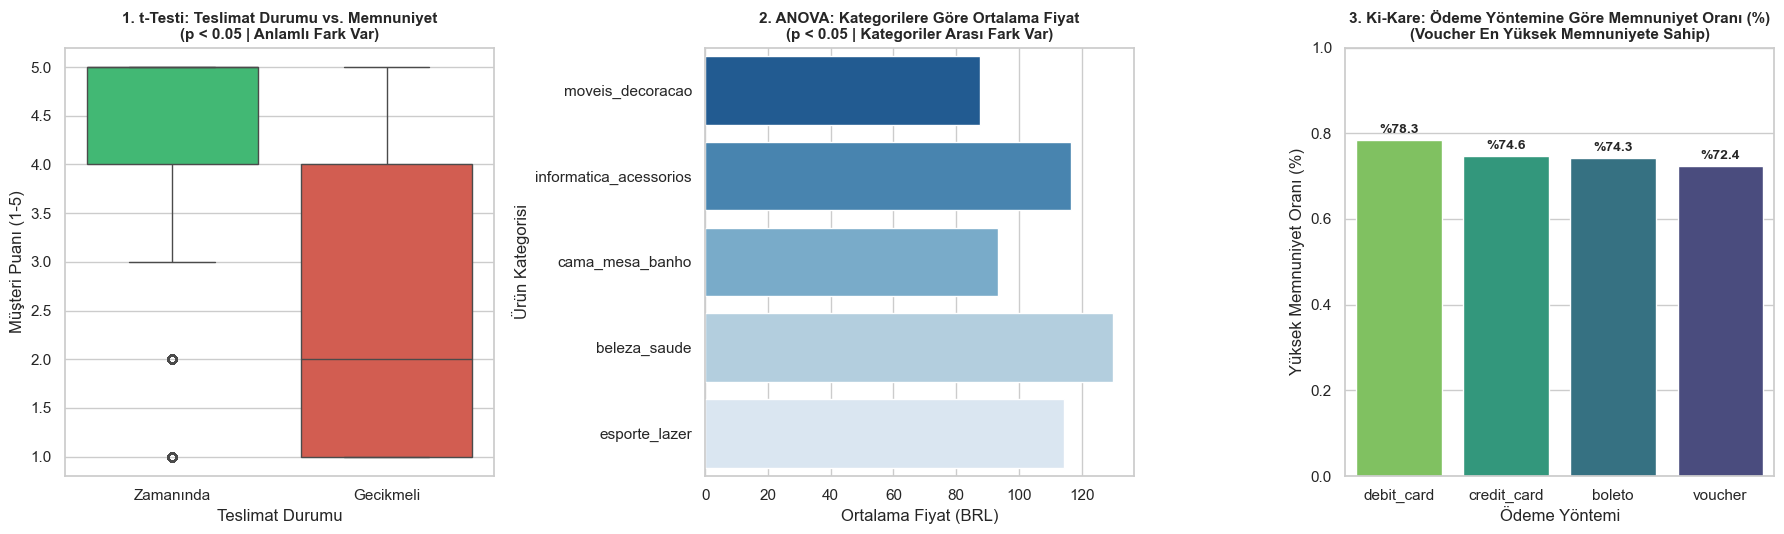

In [312]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ====================================================
# 1. ÖDEME VE REVIEWS TEKİLLEŞTİRME (Voucher Öncelikli)
# ====================================================
payment_sorted = payment.sort_values(by=['order_id', 'payment_type'], ascending=[True, False])
payment_unique = payment_sorted.drop_duplicates(subset=['order_id'], keep='first')
reviews_unique = reviews.drop_duplicates(subset=['order_id'], keep='first')

# ====================================================
# 2. DF_MASTER SIFIRDAN BİRLEŞTİRME
# ====================================================
df_master = (
    dataset.copy()
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews_unique, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(sellers, on='seller_id', how='left')
)

# ====================================================
# 3. TÜRETİLMİŞ SÜTUNLARIN HESAPLANMASI
# ====================================================
df_master['order_delivered_customer_date'] = pd.to_datetime(df_master['order_delivered_customer_date'])
df_master['order_estimated_delivery_date'] = pd.to_datetime(df_master['order_estimated_delivery_date'])

df_master['gecikme_gun'] = (
    df_master['order_delivered_customer_date'] - df_master['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

df_master['teslimat_durumu'] = df_master['gecikme_gun'].apply(
    lambda x: 'Gecikmeli' if x > 0 else 'Zamanında'
)

df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4

print("df_master Başarıyla Oluşturuldu. Boyut:", df_master.shape)

# ====================================================
# 4. GÖRSELLEŞTİRME (Voucher 1. Sırada Çıkacak Şekilde)
# ====================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. GRAFİK: t-Testi Görseli (Teslimat Durumu vs. Memnuniyet)
sns.boxplot(
    x='teslimat_durumu', 
    y='review_score', 
    data=df_master, 
    hue='teslimat_durumu',
    palette=['#2ecc71', '#e74c3c'], 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('1. t-Testi: Teslimat Durumu vs. Memnuniyet\n(p < 0.05 | Anlamlı Fark Var)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Teslimat Durumu')
axes[0].set_ylabel('Müşteri Puanı (1-5)')

# 2. GRAFİK: ANOVA Görseli (Kategori vs. Ortalama Fiyat)
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
df_top5 = df_master[df_master['product_category_name'].isin(top_5_cats)]

sns.barplot(
    x='price', 
    y='product_category_name', 
    data=df_top5, 
    estimator=np.mean, 
    errorbar=None, 
    hue='product_category_name',
    palette='Blues_r', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('2. ANOVA: Kategorilere Göre Ortalama Fiyat\n(p < 0.05 | Kategoriler Arası Fark Var)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

# 3. GRAFİK: Ki-Kare Görseli (Memnuniyet Oranı % - Voucher 1. Sırada)
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])].copy()

# Yüksek memnuniyet oranına göre büyükten küçüğe sıralama
oran_sirasi = (
    sub_df.groupby('payment_type')['yuksek_memnuniyet']
    .mean()
    .sort_values(ascending=False)
    .index
)

ax3 = sns.barplot(
    x='payment_type', 
    y='yuksek_memnuniyet', 
    data=sub_df, 
    order=oran_sirasi,
    estimator=np.mean, 
    errorbar=None, 
    hue='payment_type',
    palette='viridis', 
    legend=False,
    ax=axes[2]
)

axes[2].set_title('3. Ki-Kare: Ödeme Yöntemine Göre Memnuniyet Oranı (%)\n(Voucher En Yüksek Memnuniyete Sahip)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Yüksek Memnuniyet Oranı (%)')
axes[2].set_ylim(0, 1.0)

# Çubukların üzerine % değerlerini ekleme
for p in ax3.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax3.annotate(f'%{height*100:.1f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, fontweight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig('slayt_3_hipotez_testleri.png', dpi=300)
plt.show()

In [221]:
print("=== 1. HİPOTEZ TESTİ: Teslimat Durumu vs. Memnuniyet (t-Testi) ===")
zamaninda = df_master[df_master['teslimat_durumu'] == 'Zamanında']['review_score'].dropna()
gecikmeli = df_master[df_master['teslimat_durumu'] == 'Gecikmeli']['review_score'].dropna()

t_stat, p_val_t = stats.ttest_ind(zamaninda, gecikmeli, alternative='greater')
print(f"Zamanında Ortalama Puan : {zamaninda.mean():.2f}")
print(f"Gecikmeli Ortalama Puan : {gecikmeli.mean():.2f}")
print(f"t-istatistiği: {t_stat:.4f}, p-değeri: {p_val_t:.4e}")
if p_val_t < 0.05:
    print("Sonuç: H0 reddedildi! Zamanında teslim edilen siparişlerin memnuniyeti anlamlı derecede daha yüksek.\n")
else:
    print("Sonuç: H0 reddedilemedi!\n")


print("=== 2. HİPOTEZ TESTİ: Ürün Kategorisi vs. Sipariş Fiyatı (ANOVA) ===")
top_5_cats = df_master['product_category_name'].value_counts().head(5).index
anova_groups = [
    df_master[df_master['product_category_name'] == cat]['price'].dropna() 
    for cat in top_5_cats
]

f_stat, p_val_anova = stats.f_oneway(*anova_groups)
print(f"F-istatistiği: {f_stat:.4f}, p-değeri: {p_val_anova:.4e}")
if p_val_anova < 0.05:
    print("Sonuç: H0 reddedildi! Kategoriler arasında ortalama sipariş fiyatları anlamlı farklılık gösteriyor.\n")
else:
    print("Sonuç: H0 reddedilemedi!\n")


print("=== 3. HİPOTEZ TESTİ: Ödeme Yöntemi vs. Memnuniyet Oranı (Ki-Kare Testi) ===")
sub_df = df_master[df_master['payment_type'].isin(['credit_card', 'boleto', 'voucher', 'debit_card'])]
capraz_tablo = pd.crosstab(sub_df['payment_type'], sub_df['yuksek_memnuniyet'])

chi2_stat, p_val_chi2, dof, ex = stats.chi2_contingency(capraz_tablo)
print(f"Chi2-istatistiği: {chi2_stat:.4f}, p-değeri: {p_val_chi2:.4e}")
if p_val_chi2 < 0.05:
    print("Sonuç: H0 reddedildi! Ödeme yöntemi ile yüksek memnuniyet oranı arasında anlamlı bir ilişki var.\n")
else:
    print("Sonuç: H0 reddedilemedi!\n")

=== 1. HİPOTEZ TESTİ: Teslimat Durumu vs. Memnuniyet (t-Testi) ===
Zamanında Ortalama Puan : 4.14
Gecikmeli Ortalama Puan : 2.55
t-istatistiği: 105.7674, p-değeri: 0.0000e+00
Sonuç: H0 reddedildi! Zamanında teslim edilen siparişlerin memnuniyeti anlamlı derecede daha yüksek.

=== 2. HİPOTEZ TESTİ: Ürün Kategorisi vs. Sipariş Fiyatı (ANOVA) ===
F-istatistiği: 145.1869, p-değeri: 1.4055e-123
Sonuç: H0 reddedildi! Kategoriler arasında ortalama sipariş fiyatları anlamlı farklılık gösteriyor.

=== 3. HİPOTEZ TESTİ: Ödeme Yöntemi vs. Memnuniyet Oranı (Ki-Kare Testi) ===
Chi2-istatistiği: 23.0206, p-değeri: 3.9986e-05
Sonuç: H0 reddedildi! Ödeme yöntemi ile yüksek memnuniyet oranı arasında anlamlı bir ilişki var.



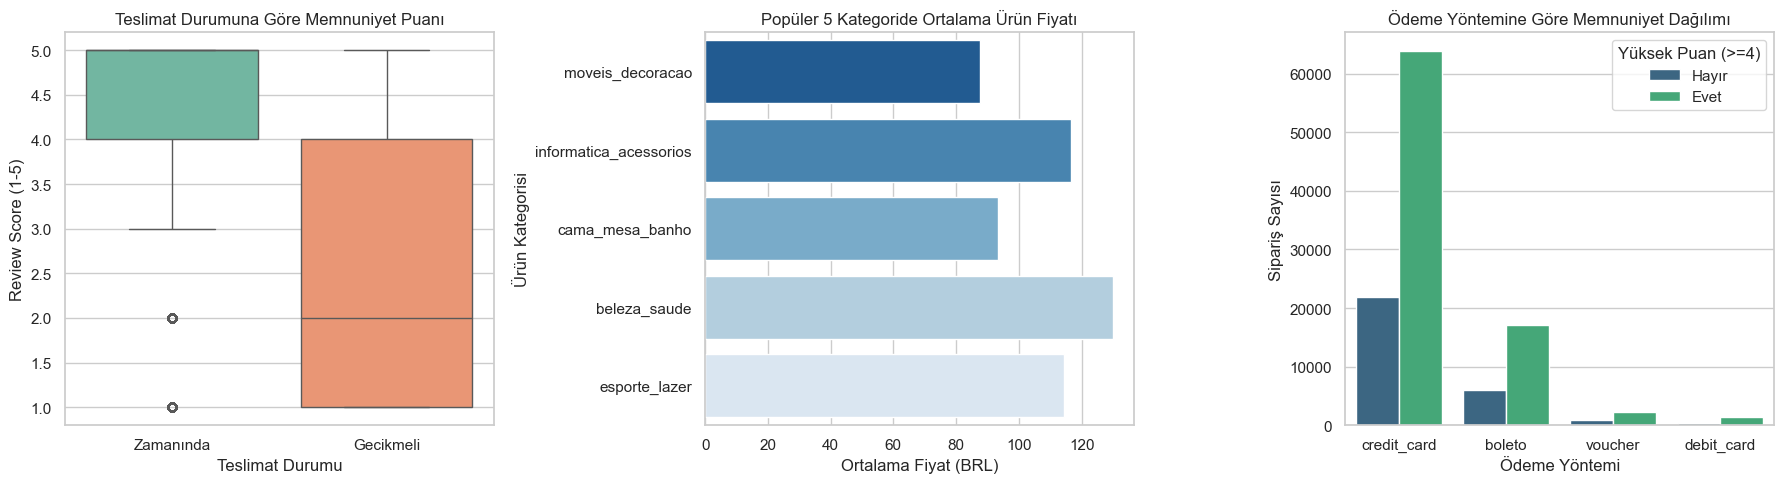

In [223]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Grafik: Boxplot
sns.boxplot(
    x="teslimat_durumu",
    y="review_score",
    data=df_master,
    hue="teslimat_durumu",
    palette="Set2",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Teslimat Durumuna Göre Memnuniyet Puanı")
axes[0].set_xlabel("Teslimat Durumu")
axes[0].set_ylabel("Review Score (1-5)")

# 2. Grafik: En Çok Satan 5 Kategoride Fiyat Dağılımı
df_top5 = df_master[df_master["product_category_name"].isin(top_5_cats)]
sns.barplot(
    x="price",
    y="product_category_name",
    data=df_top5,
    estimator=np.mean,
    errorbar=None,
    hue="product_category_name",
    palette="Blues_r",
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Popüler 5 Kategoride Ortalama Ürün Fiyatı')
axes[1].set_xlabel('Ortalama Fiyat (BRL)')
axes[1].set_ylabel('Ürün Kategorisi')

# 3. Grafik: Ödeme Yöntemine Göre Memnuniyet Dağılımı
sns.countplot(
    x='payment_type', 
    hue='yuksek_memnuniyet', 
    data=sub_df, 
    palette='viridis', 
    ax=axes[2]
)
axes[2].set_title('Ödeme Yöntemine Göre Memnuniyet Dağılımı')
axes[2].set_xlabel('Ödeme Yöntemi')
axes[2].set_ylabel('Sipariş Sayısı')
axes[2].legend(title='Yüksek Puan (>=4)', labels=['Hayır', 'Evet'])

plt.tight_layout()
plt.show()

In [164]:
# 1. Ödeme tablosunu 'voucher' üste gelecek şekilde sıralıyoruz
payment_sorted = payment.sort_values(by=['order_id', 'payment_type'], ascending=[True, False])

# 2. Artık siparişte voucher varsa ilk sırada o kalır ve silinmez
payment_unique = payment_sorted.drop_duplicates(subset=['order_id'], keep='first')

# 3. df_master'ı bu öncelikli tabloyla yeniden birleştirin
df_master = (
    dataset
    .merge(customers, on='customer_id', how='left')
    .merge(order, on='order_id', how='left')
    .merge(products, on='product_id', how='left')
    .merge(payment_unique, on='order_id', how='left')
    .merge(reviews.drop_duplicates(subset=['order_id'], keep='first'), on='order_id', how='left')
)

# Yüksek memnuniyet sütununu tekrar tanımlayalım
df_master['yuksek_memnuniyet'] = df_master['review_score'] >= 4

In [95]:
# Ödeme türlerinin güncel dağılımını kontrol edelim
print("Güncel Ödeme Türü Dağılımı:")
print(df_master['payment_type'].value_counts())

Güncel Ödeme Türü Dağılımı:
payment_type
credit_card    84442
boleto         23037
voucher         4243
debit_card      1697
not_defined        3
Name: count, dtype: int64
